# SO SÁNH CÁC BASELINE MODELS: LOGISTIC REGRESSION vs XGBOOST vs MLP (RAW DATA)

Notebook này thiết lập các Baseline cho bài toán dự đoán ý định mua hàng (Online Shoppers Purchasing Intention):
1. **Logistic Regression (Baseline):** Tiền xử lý tối thiểu (One-Hot Encoder cho categorical, passthrough numerical).
2. **XGBoost (Baseline):** Sử dụng enable_categorical=True trên dữ liệu thô
3. **Multi-Layer Perceptron (Deep Learning Baseline):** PyTorch MLP 16-8-1

In [ ]:
# Tự động kết nối Google Drive nếu đang chạy trên Google Colab
import os
import sys

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    PROJECT_DIR = '/content/drive/MyDrive/DL_Business'
    if os.path.exists(PROJECT_DIR):
        os.chdir(PROJECT_DIR)
        if PROJECT_DIR not in sys.path:
            sys.path.insert(0, PROJECT_DIR)
        print(f"✓ Đã kết nối thành công! Thư mục hiện tại: {os.getcwd()}")
    else:
        print(f"⚠️ Không tìm thấy đường dẫn: {PROJECT_DIR}")
        print("Vui lòng kiểm tra lại tên thư mục trên Drive của bạn.")


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    precision_recall_curve
)

import torch

# Import các công cụ đánh giá, ghi nhận và mô hình PyTorch MLP từ logger.py & visualization.py
from logger import (
    get_cv_scorers,
    log_experiment,
    load_experiments_df,
    load_experiments_json,
    DEVICE,
    MLPNet,
    train_pytorch_mlp,
    predict_proba_mlp,
    cross_validate_mlp
)
from visualization import (
    plot_confusion_matrix,
    plot_pr_curve,
    plot_learning_curves
)

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.4f' % x)

# ==========================================
# HYPERPARAMETERS & REPRODUCIBILITY CONFIG
# ==========================================
RANDOM_STATE = 42
TEST_SIZE = 0.2
N_SPLITS = 4
N_REPEATS = 3


Mounted at /content/drive
-> Đã chuyển thư mục làm việc sang Google Drive: /content/drive/MyDrive/DL_Business


## 1. Đọc dữ liệu & Chia tập (Train 80% / Test 20%)
Cố định `stratify=y` và `random_state=42` để bảo toàn tỷ lệ nhãn dương (~15.49%).

In [2]:
# 1. Đọc dữ liệu
df = pd.read_csv('online_shoppers_intention.csv')

# 2. Loại bỏ duplicate
n_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
n_removed = n_before - len(df)

print(f"-> Số dòng duplicate đã loại bỏ: {n_removed:,}")

# 3. Tách X và y
X = df.drop(columns=['Revenue'])
y = df['Revenue'].astype(int)

# 4. Phân tách Train/Test 80/20 có phân tầng
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
    shuffle=True
)

print(f"-> Tập Train: {X_train.shape[0]:,} phiên (Tỷ lệ mua: {y_train.mean()*100:.2f}%)")
print(f"-> Tập Test:  {X_test.shape[0]:,} phiên (Tỷ lệ mua: {y_test.mean()*100:.2f}%)")

-> Số dòng duplicate đã loại bỏ: 125
-> Tập Train: 9,764 phiên (Tỷ lệ mua: 15.63%)
-> Tập Test:  2,441 phiên (Tỷ lệ mua: 15.65%)


## 2. Xây dựng Pipeline Baseline
- **Biến số (Numerical)**: `'passthrough'` để đồng bộ thang đo phục vụ Logistic Regression.
- **Biến phân loại (Categorical)**: `OneHotEncoder(drop='first', handle_unknown='ignore')`.
- **Mô hình**: `LogisticRegression(max_iter=1000, random_state=42)` mặc định.

In [3]:
num_cols = [
    'Administrative', 'Administrative_Duration',
    'Informational', 'Informational_Duration',
    'ProductRelated', 'ProductRelated_Duration',
    'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay'
]

cat_cols = ['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']

# Bộ tiền xử lý tích hợp
preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', num_cols),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), cat_cols)
    ]
)

# Đóng gói thành Pipeline hoàn chỉnh
baseline_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

print("Pipeline Baseline đã được khởi tạo thành công!")

Pipeline Baseline đã được khởi tạo thành công!


## 3. Thẩm định chéo Logistic Regression (Repeated Stratified K-Fold trên Train)

Chạy 4 folds lặp lại 3 lần (**12 lượt đánh giá độc lập**) trên tập Train. Toàn bộ các bước tiền xử lý (One-Hot Encoding) được đóng gói trong Pipeline để **ngăn ngừa rò rỉ dữ liệu (Data Leakage)** giữa các fold.

In [4]:
rskf = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=RANDOM_STATE)

# 1. Thẩm định chéo 12 lượt với bộ scorers chuẩn hóa (logger.get_cv_scorers)
cv_results_lr = cross_validate(
    baseline_pipeline,
    X_train, y_train,
    cv=rskf,
    scoring=get_cv_scorers(),
    n_jobs=-1
)

# 2. Bảng tổng kết đối chiếu toàn diện cả 2 lớp theo quy chuẩn (mean ± std, %)
metrics_map = [
    ('CV AP (%)', cv_results_lr['test_ap']),
    ('CV Precision (Mua) (%)', cv_results_lr['test_prec_1']),
    ('CV Recall (Mua) (%)', cv_results_lr['test_rec_1']),
    ('CV F1 (Mua) (%)', cv_results_lr['test_f1_1']),
    ('CV Precision (Không mua) (%)', cv_results_lr['test_prec_0']),
    ('CV Recall (Không mua) (%)', cv_results_lr['test_rec_0']),
    ('CV F1 (Không mua) (%)', cv_results_lr['test_f1_0']),
]

lr_cv_summary = pd.DataFrame({
    'Chỉ số đánh giá': [m[0] for m in metrics_map],
    'Điểm trung bình (Mean %)': [f"{m[1].mean() * 100:.2f}%" for m in metrics_map],
    'Độ lệch chuẩn (Std %)': [f"{m[1].std() * 100:.2f}%" for m in metrics_map],
    'mean ± std (%)': [f"{m[1].mean() * 100:.2f} ± {m[1].std() * 100:.2f}" for m in metrics_map]
})

display(lr_cv_summary.set_index('Chỉ số đánh giá'))


,Điểm trung bình (Mean %),Độ lệch chuẩn (Std %),mean ± std (%)
Chỉ số đánh giá,,,
CV AP (%),63.54%,2.63%,63.54 ± 2.63
CV Precision (Mua) (%),73.37%,3.63%,73.37 ± 3.63
CV Recall (Mua) (%),37.35%,1.94%,37.35 ± 1.94
CV F1 (Mua) (%),49.45%,1.95%,49.45 ± 1.95
CV Precision (Không mua) (%),89.36%,0.29%,89.36 ± 0.29
CV Recall (Không mua) (%),97.47%,0.50%,97.47 ± 0.50
CV F1 (Không mua) (%),93.24%,0.28%,93.24 ± 0.28


## 4. Huấn luyện trên toàn bộ Train & Đánh giá trên Hold-out Test (20%)

Kiểm thử khả năng tổng quát hóa trên tập dữ liệu độc lập chưa từng xuất hiện trong quá trình huấn luyện.

In [5]:
# Fit pipeline trên toàn bộ tập Train
baseline_pipeline.fit(X_train, y_train)

# Dự đoán trên tập Test
y_pred = baseline_pipeline.predict(X_test)
y_proba = baseline_pipeline.predict_proba(X_test)[:, 1]

print("=== BÁO CÁO PHÂN LỚP TẬP TEST (LOGISTIC REGRESSION BASELINE) ===")
print(classification_report(y_test, y_pred, target_names=['0 = Không mua', '1 = Mua'], digits=4))
print(f"-> Test AP (Average Precision): {average_precision_score(y_test, y_proba) * 100:.2f}% (Ngưỡng = 0.50)")


=== BÁO CÁO PHÂN LỚP TẬP TEST (LOGISTIC REGRESSION BASELINE) ===
               precision    recall  f1-score   support

0 = Không mua     0.9000    0.9752    0.9361      2059
      1 = Mua     0.7571    0.4162    0.5372       382

     accuracy                         0.8878      2441
    macro avg     0.8286    0.6957    0.7366      2441
 weighted avg     0.8777    0.8878    0.8737      2441

-> Test AP (Average Precision): 65.53% (Ngưỡng = 0.50)


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


---
# PHẦN 2: XGBOOST BASELINE (NATIVE CATEGORICAL - RAW DATA)

> **Điểm mạnh của XGBoost trên dữ liệu thô:**
- Hỗ trợ trực tiếp dữ liệu danh mục thông qua tham số `enable_categorical=True` mà không cần One-Hot Encoding trước.
- Thuật toán cây quyết định tự nhiên bất biến với phép co giãn đơn điệu (Monotonic scaling), do đó không yêu cầu co giãn các biến số (`StandardScaler`).

## 5. Chuẩn bị dữ liệu danh mục & Khởi tạo XGBoost Baseline

In [6]:
from xgboost import XGBClassifier

# 1. Tiền xử lý tối thiểu: Chuẩn hóa CategoricalDtype đồng bộ giữa Train và Test
# Lưu ý: Cần dùng pd.CategoricalDtype lấy toàn bộ categories từ df gốc để:
# - Đảm bảo X_train_xgb và X_test_xgb có cùng danh mục & thứ tự categories (tránh lỗi mismatch trên XGBoost C++)
# - Tránh lỗi Boolean category (chuyển sang str trước khi cast)
X_train_xgb = X_train.copy()
X_test_xgb = X_test.copy()

for col in cat_cols:
    cat_type = pd.CategoricalDtype(categories=df[col].astype(str).unique().tolist())
    X_train_xgb[col] = X_train_xgb[col].astype(str).astype(cat_type)
    X_test_xgb[col] = X_test_xgb[col].astype(str).astype(cat_type)

# 2. Khởi tạo XGBoost Baseline mặc định
xgb_baseline = XGBClassifier(
    enable_categorical=True,
    random_state=RANDOM_STATE,
    eval_metric='logloss'
)

print("Khởi tạo XGBoost Baseline thành công!")


Khởi tạo XGBoost Baseline thành công!


## 6. Thẩm định chéo XGBoost (Repeated Stratified K-Fold trên Train)

Chạy 12 lượt đánh giá độc lập với cùng bộ `rskf` đã sử dụng cho Logistic Regression để đảm bảo tính công bằng tuyệt đối.

In [7]:
cv_results_xgb = cross_validate(
    xgb_baseline,
    X_train_xgb, y_train,
    cv=rskf,
    scoring=get_cv_scorers(),
    n_jobs=-1
)

metrics_map_xgb = [
    ('CV AP (%)', cv_results_xgb['test_ap']),
    ('CV Precision (Mua) (%)', cv_results_xgb['test_prec_1']),
    ('CV Recall (Mua) (%)', cv_results_xgb['test_rec_1']),
    ('CV F1 (Mua) (%)', cv_results_xgb['test_f1_1']),
    ('CV Precision (Không mua) (%)', cv_results_xgb['test_prec_0']),
    ('CV Recall (Không mua) (%)', cv_results_xgb['test_rec_0']),
    ('CV F1 (Không mua) (%)', cv_results_xgb['test_f1_0']),
]

xgb_cv_summary = pd.DataFrame({
    'Chỉ số đánh giá': [m[0] for m in metrics_map_xgb],
    'Điểm trung bình (Mean %)': [f"{m[1].mean() * 100:.2f}%" for m in metrics_map_xgb],
    'Độ lệch chuẩn (Std %)': [f"{m[1].std() * 100:.2f}%" for m in metrics_map_xgb],
    'mean ± std (%)': [f"{m[1].mean() * 100:.2f} ± {m[1].std() * 100:.2f}" for m in metrics_map_xgb]
})

display(xgb_cv_summary.set_index('Chỉ số đánh giá'))


,Điểm trung bình (Mean %),Độ lệch chuẩn (Std %),mean ± std (%)
Chỉ số đánh giá,,,
CV AP (%),71.21%,1.85%,71.21 ± 1.85
CV Precision (Mua) (%),69.63%,2.59%,69.63 ± 2.59
CV Recall (Mua) (%),58.19%,1.64%,58.19 ± 1.64
CV F1 (Mua) (%),63.38%,1.67%,63.38 ± 1.67
CV Precision (Không mua) (%),92.48%,0.29%,92.48 ± 0.29
CV Recall (Không mua) (%),95.28%,0.57%,95.28 ± 0.57
CV F1 (Không mua) (%),93.86%,0.34%,93.86 ± 0.34


## 7. Đánh giá XGBoost trên tập Hold-out Test (20%)

Huấn luyện trên toàn bộ `X_train_xgb` và kiểm tra khả năng suy luận trên `X_test_xgb`.

In [8]:
xgb_baseline.fit(X_train_xgb, y_train)

y_pred_xgb = xgb_baseline.predict(X_test_xgb)
y_proba_xgb = xgb_baseline.predict_proba(X_test_xgb)[:, 1]

print("=== BÁO CÁO PHÂN LỚP TẬP TEST (XGBOOST BASELINE) ===")
print(classification_report(y_test, y_pred_xgb, target_names=['0 = Không mua', '1 = Mua'], digits=4))
print(f"-> Test AP (Average Precision): {average_precision_score(y_test, y_proba_xgb) * 100:.2f}% (Ngưỡng = 0.50)")


=== BÁO CÁO PHÂN LỚP TẬP TEST (XGBOOST BASELINE) ===
               precision    recall  f1-score   support

0 = Không mua     0.9283    0.9495    0.9388      2059
      1 = Mua     0.6896    0.6047    0.6444       382

     accuracy                         0.8955      2441
    macro avg     0.8089    0.7771    0.7916      2441
 weighted avg     0.8909    0.8955    0.8927      2441

-> Test AP (Average Precision): 71.94% (Ngưỡng = 0.50)


---
# PHẦN 3: MULTI-LAYER PERCEPTRON (MLP) BASELINE (PYTORCH - RAW DATA)

Thử nghiệm mô hình MLP  đóng vai trò là **Deep Learning Baseline** trên tập dữ liệu thô (Numerical: Passthrough, Categorical: OneHotEncoder).
- **Kiến trúc mạng:**
  - **Lớp 1 (Layer 1):** 16 neurons + Hàm kích hoạt `ReLU`
  - **Lớp 2 (Layer 2):** 8 neurons + Hàm kích hoạt `ReLU`
  - **Lớp đầu ra (Output):** 1 neuron + Hàm kích hoạt `Sigmoid` (xác suất mua hàng $P(Revenue=1)$)
- **Chiến lược huấn luyện:** Optimizer Adam ($lr=0.002, \text{weight_decay}=10^{-4}$), Binary Cross Entropy Loss (`BCELoss`), Early Stopping (patience=8, đánh giá trên 15% validation nội bộ).
- **Đánh giá:** Lặp trực tiếp qua 12 Folds của `rskf`, cô lập `preprocessor` trong từng fold để chống rò rỉ dữ liệu tuyệt đối.

## 8. Xây dựng Kiến trúc MLP & Hàm huấn luyện PyTorch trực tiếp

In [9]:
# ==============================================================================
# THIẾT LẬP MÔ HÌNH PYTORCH MLP BASELINE (TÁI SỬ DỤNG TỪ LOGGER.PY)
# ==============================================================================
# Kiến trúc MLPNet (Dropout 0.2), train_pytorch_mlp (weight_decay 1e-3, test_size 0.15),
# predict_proba_mlp và cross_validate_mlp được tái sử dụng trực tiếp từ logger.py
print(f"-> Thiết bị tính toán cho MLP Baseline: {DEVICE}")
if torch.cuda.is_available():
    print(f"   Tên GPU: {torch.cuda.get_device_name(0)}")
print("-> Đã sẵn sàng kiến trúc MLPNet và các hàm huấn luyện/CV từ logger.py!")


-> Thiết bị tính toán cho MLP Baseline: cuda
   Tên GPU: Tesla T4
-> Đã sẵn sàng kiến trúc MLPNet và các hàm huấn luyện/CV từ logger.py!


## 9. Thẩm định chéo MLP Baseline (Repeated Stratified K-Fold trên Train)

In [10]:
print("-> Đang thực hiện 12-Fold Cross-Validation cho MLP Baseline trên tập Train...\n")
cv_results_mlp = cross_validate_mlp(
    X_train,
    y_train,
    preprocessor_base=preprocessor,
    cv_splitter=rskf,
    random_state=RANDOM_STATE
)

print("="*65)
print("KẾT QUẢ THẨM ĐỊNH CHÉO (12 FOLDS) - MLP BASELINE (RAW DATA):")
print("="*65)
print(f"* CV AP (Độ đo chính):           {cv_results_mlp['test_ap'].mean()*100:6.2f}% ± {cv_results_mlp['test_ap'].std()*100:4.2f}%")
print(f"* CV Precision (Lớp Mua - 1):    {cv_results_mlp['test_prec_1'].mean()*100:6.2f}% ± {cv_results_mlp['test_prec_1'].std()*100:4.2f}%")
print(f"* CV Recall (Lớp Mua - 1):       {cv_results_mlp['test_rec_1'].mean()*100:6.2f}% ± {cv_results_mlp['test_rec_1'].std()*100:4.2f}%")
print(f"* CV F1-Score (Lớp Mua - 1):     {cv_results_mlp['test_f1_1'].mean()*100:6.2f}% ± {cv_results_mlp['test_f1_1'].std()*100:4.2f}%")
print(f"* CV F1-Macro:                   {cv_results_mlp['test_f1_macro'].mean()*100:6.2f}% ± {cv_results_mlp['test_f1_macro'].std()*100:4.2f}%")

-> Đang thực hiện 12-Fold Cross-Validation cho MLP Baseline trên tập Train...



/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2, 4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown ca

KẾT QUẢ THẨM ĐỊNH CHÉO (12 FOLDS) - MLP BASELINE (RAW DATA):
* CV AP (Độ đo chính):            66.16% ± 2.07%
* CV Precision (Lớp Mua - 1):     76.82% ± 5.03%
* CV Recall (Lớp Mua - 1):        35.91% ± 8.84%
* CV F1-Score (Lớp Mua - 1):      48.05% ± 7.34%
* CV F1-Macro:                    70.68% ± 3.82%


## 10. Huấn luyện toàn Train & Đánh giá MLP Baseline trên Hold-out Test (20%)

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


BÁO CÁO PHÂN LOẠI CHI TIẾT - MLP BASELINE (HOLD-OUT TEST):
               precision    recall  f1-score   support

Không mua (0)     0.9045    0.9709    0.9365      2059
      Mua (1)     0.7403    0.4476    0.5579       382

     accuracy                         0.8890      2441
    macro avg     0.8224    0.7093    0.7472      2441
 weighted avg     0.8788    0.8890    0.8773      2441

-> Test AP (Average Precision): 66.88% (Ngưỡng = 0.50)

TIẾN TRÌNH HUẤN LUYỆN (LEARNING CURVES) - MLP BASELINE TRÊN TẬP TRAIN & VAL NỘI BỘ:


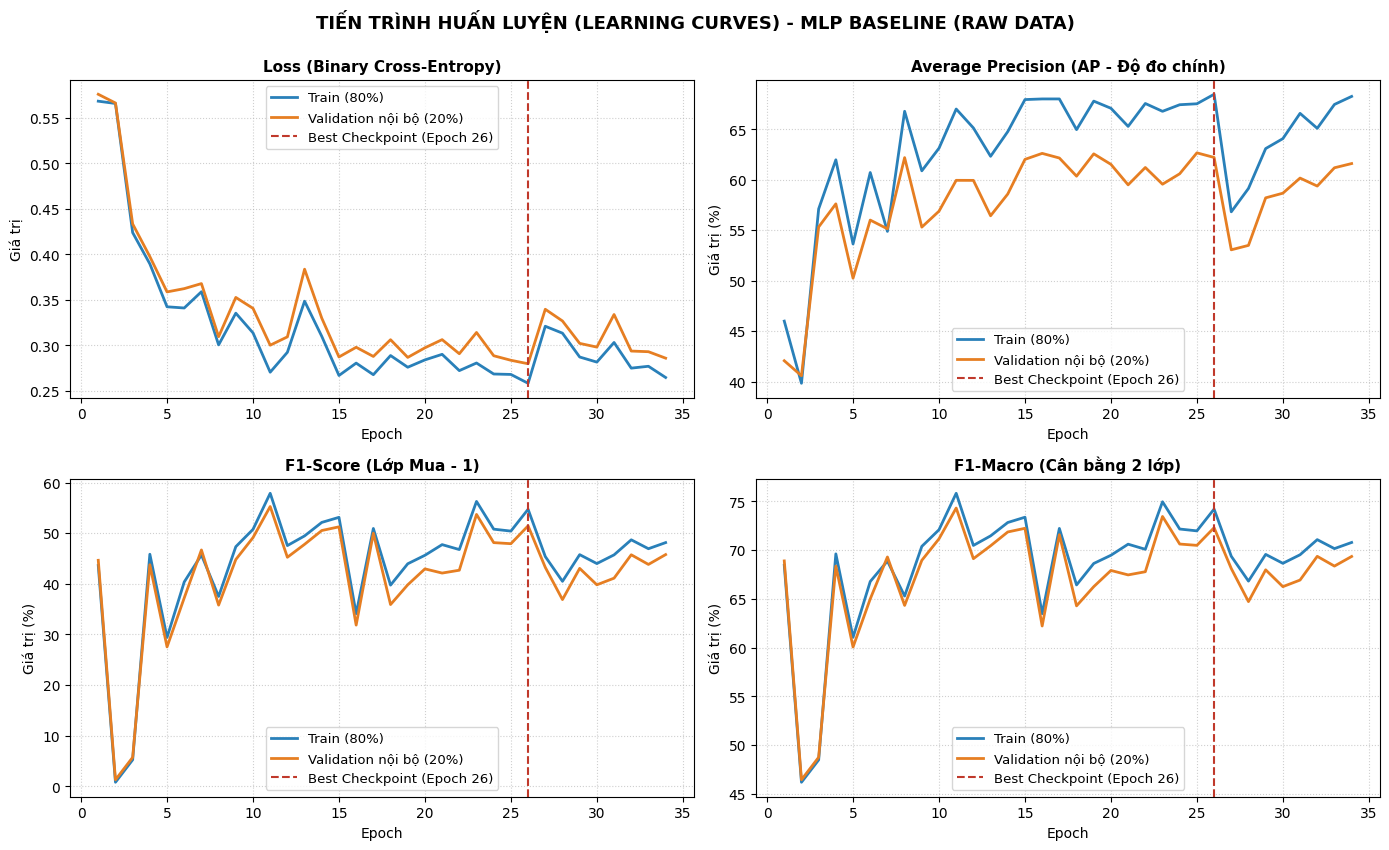

In [11]:
# 1. Huấn luyện trên toàn bộ tập Train (test_size=0.2 cho validation nội bộ, ghi nhận learning curves)
prep_mlp_full, model_mlp_full, hist_mlp_full = train_pytorch_mlp(
    X_train, y_train, preprocessor_base=preprocessor,
    random_state=RANDOM_STATE, return_history=True, test_size=0.2
)

# 2. Dự đoán xác suất và nhãn trên tập Test
y_proba_mlp = predict_proba_mlp(prep_mlp_full, model_mlp_full, X_test)
y_pred_mlp = (y_proba_mlp >= 0.5).astype(int)

print("="*65)
print("BÁO CÁO PHÂN LOẠI CHI TIẾT - MLP BASELINE (HOLD-OUT TEST):")
print("="*65)
print(classification_report(y_test, y_pred_mlp, target_names=['Không mua (0)', 'Mua (1)'], digits=4))
print(f"-> Test AP (Average Precision): {average_precision_score(y_test, y_proba_mlp) * 100:.2f}% (Ngưỡng = 0.50)")

# 3. Trực quan hóa tiến trình huấn luyện (Learning Curves)
print("\n" + "="*80)
print("TIẾN TRÌNH HUẤN LUYỆN (LEARNING CURVES) - MLP BASELINE TRÊN TẬP TRAIN & VAL NỘI BỘ:")
print("="*80)
plot_learning_curves(hist_mlp_full, model_title="MLP Baseline (Raw Data)")


---
# PHẦN 4: TỔNG KẾT & SO SÁNH ĐỐI ĐẦU 3 BASELINES (LR vs XGBOOST vs MLP)

## 11. So sánh đối đầu trực diện 3 Mô hình Baseline trên tập Test độc lập

Bao gồm:
1. Bảng số liệu tổng hợp đối đầu trên tập Test (ngưỡng phân loại mặc định 0.50).
2. Trực quan hóa Ma trận nhầm lẫn (Confusion Matrix) của cả 3 mô hình trên cùng 1 hàng 3 cột để dễ dàng so sánh tỷ lệ nhầm lẫn.
3. Biểu đồ đường cong Precision-Recall Curve (PR Curve) đối chiếu trực tiếp giữa 3 mô hình.

BẢNG SO SÁNH ĐỐI ĐẦU 3 BASELINES TRÊN TẬP KIỂM ĐỊNH HOLD-OUT TEST:


,Độ đo (Hold-out Test @0.50),Logistic Regression,XGBoost,MLP (PyTorch)
0,Test AP (%),65.53%,71.94%,66.88%
1,Test Precision (Mua) (%),75.71%,68.96%,74.03%
2,Test Recall (Mua) (%),41.62%,60.47%,44.76%
3,Test F1 (Mua) (%),53.72%,64.44%,55.79%
4,Test F1-Macro (%),73.66%,79.16%,74.72%
5,Test Accuracy (%),88.78%,89.55%,88.90%


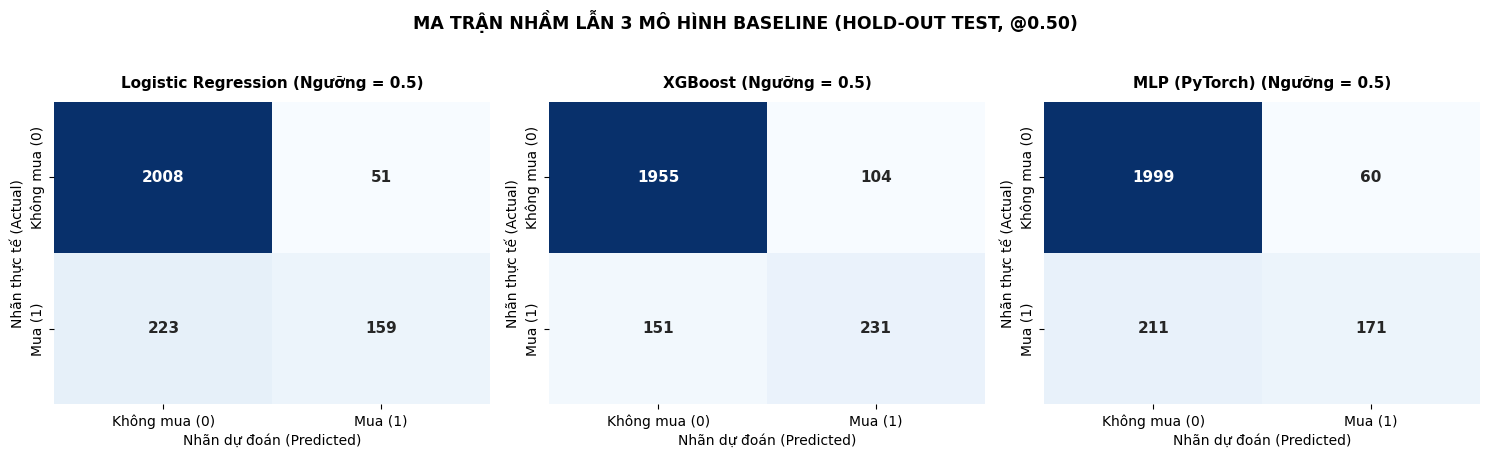

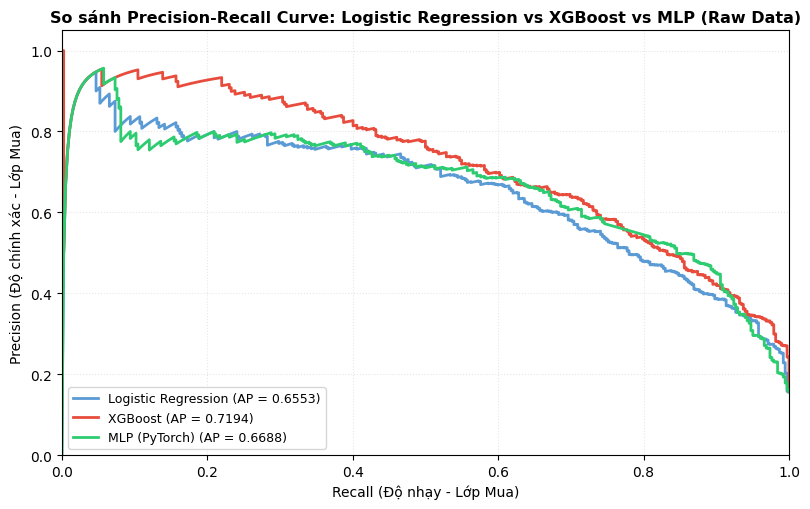

In [12]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 1. Bảng đối chiếu các chỉ số đánh giá trên tập Hold-out Test (@0.50)
metrics_3_models = [
    ('Test AP (%)',
     average_precision_score(y_test, y_proba) * 100,
     average_precision_score(y_test, y_proba_xgb) * 100,
     average_precision_score(y_test, y_proba_mlp) * 100),
    ('Test Precision (Mua) (%)',
     precision_score(y_test, y_pred, pos_label=1) * 100,
     precision_score(y_test, y_pred_xgb, pos_label=1) * 100,
     precision_score(y_test, y_pred_mlp, pos_label=1) * 100),
    ('Test Recall (Mua) (%)',
     recall_score(y_test, y_pred, pos_label=1) * 100,
     recall_score(y_test, y_pred_xgb, pos_label=1) * 100,
     recall_score(y_test, y_pred_mlp, pos_label=1) * 100),
    ('Test F1 (Mua) (%)',
     f1_score(y_test, y_pred, pos_label=1) * 100,
     f1_score(y_test, y_pred_xgb, pos_label=1) * 100,
     f1_score(y_test, y_pred_mlp, pos_label=1) * 100),
    ('Test F1-Macro (%)',
     f1_score(y_test, y_pred, average='macro') * 100,
     f1_score(y_test, y_pred_xgb, average='macro') * 100,
     f1_score(y_test, y_pred_mlp, average='macro') * 100),
    ('Test Accuracy (%)',
     accuracy_score(y_test, y_pred) * 100,
     accuracy_score(y_test, y_pred_xgb) * 100,
     accuracy_score(y_test, y_pred_mlp) * 100)
]

df_compare_3 = pd.DataFrame(
    [(m[0], f"{m[1]:.2f}%", f"{m[2]:.2f}%", f"{m[3]:.2f}%") for m in metrics_3_models],
    columns=['Độ đo (Hold-out Test @0.50)', 'Logistic Regression', 'XGBoost', 'MLP (PyTorch)']
)

print("="*75)
print("BẢNG SO SÁNH ĐỐI ĐẦU 3 BASELINES TRÊN TẬP KIỂM ĐỊNH HOLD-OUT TEST:")
print("="*75)
display(df_compare_3)

# 2. Trực quan hóa Ma trận nhầm lẫn của cả 3 mô hình (1 hàng 3 cột)
cm_lr = confusion_matrix(y_test, y_pred)
cm_xgb = confusion_matrix(y_test, y_pred_xgb)
cm_mlp = confusion_matrix(y_test, y_pred_mlp)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
plot_confusion_matrix(cm_lr, ax=axes[0], title='Logistic Regression', threshold=0.5, cmap='Blues')
plot_confusion_matrix(cm_xgb, ax=axes[1], title='XGBoost', threshold=0.5, cmap='Blues')
plot_confusion_matrix(cm_mlp, ax=axes[2], title='MLP (PyTorch)', threshold=0.5, cmap='Blues')

plt.suptitle('MA TRẬN NHẦM LẪN 3 MÔ HÌNH BASELINE (HOLD-OUT TEST, @0.50)', fontsize=12.5, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

# 3. Vẽ đối chiếu trực tiếp đường cong Precision-Recall của cả 3 mô hình
fig, ax = plt.subplots(figsize=(8.2, 5.2))
plot_pr_curve(y_test, y_proba, model_name='Logistic Regression', ax=ax, color='#5B9BD5')
plot_pr_curve(y_test, y_proba_xgb, model_name='XGBoost', ax=ax, color='#E74C3C')
plot_pr_curve(y_test, y_proba_mlp, model_name='MLP (PyTorch)', ax=ax, color='#2ECC71')

ax.set_title('So sánh Precision-Recall Curve: Logistic Regression vs XGBoost vs MLP (Raw Data)', fontsize=11.5, fontweight='bold')
plt.tight_layout()
plt.show()


## 12. Lưu trữ kết quả các Baseline vào Lịch sử Thực nghiệm (JSON)

Ghi nhận đồng bộ toàn bộ kết quả của 3 mô hình Baseline vào file `experiment_results.json` theo đúng quy chuẩn dự án để phục vụ so sánh xuyên suốt với các thực nghiệm tiếp theo.

In [13]:
config = {
    'random_state': RANDOM_STATE,
    'test_size': TEST_SIZE,
    'n_splits': N_SPLITS,
    'n_repeats': N_REPEATS
}

# 1. Ghi nhận Logistic Regression Baseline
log_experiment(
    exp_id='exp0_baseline_logistic',
    model_name='Logistic Regression',
    notebook='exp0_baseline.ipynb',
    description='Baseline Raw Data (passthrough numerical, OHE categorical)',
    config=config,
    cv_results=cv_results_lr,
    y_test=y_test,
    y_pred=y_pred,
    y_proba=y_proba,
    threshold=0.5
)

# 2. Ghi nhận XGBoost Baseline
log_experiment(
    exp_id='exp0_baseline_xgb',
    model_name='XGBoost',
    notebook='exp0_baseline.ipynb',
    description='Baseline XGBoost (enable_categorical=True, raw data)',
    config=config,
    cv_results=cv_results_xgb,
    y_test=y_test,
    y_pred=y_pred_xgb,
    y_proba=y_proba_xgb,
    threshold=0.5
)

# 3. Ghi nhận MLP Baseline
log_experiment(
    exp_id='exp0_baseline_mlp',
    model_name='MLP (PyTorch)',
    notebook='exp0_baseline.ipynb',
    description='Baseline MLP 16-8-1 (passthrough numerical, OHE categorical)',
    config=config,
    cv_results=cv_results_mlp,
    y_test=y_test,
    y_pred=y_pred_mlp,
    y_proba=y_proba_mlp,
    threshold=0.5
)

print("\n" + "="*75)
print("BẢNG TỔNG HỢP CROSS-VALIDATION CÁC MÔ HÌNH BASELINE (12 FOLDS, %):")
display(load_experiments_df(view='cv'))

print("\n" + "="*75)
print("BẢNG TỔNG HỢP KIỂM ĐỊNH HOLD-OUT TEST CÁC MÔ HÌNH BASELINE (NGƯỠNG = 0.50, %):")
display(load_experiments_df(view='test'))


-> Đã lưu thành công thực nghiệm 'exp0_baseline_logistic' vào experiment_results.json
-> Đã lưu thành công thực nghiệm 'exp0_baseline_xgb' vào experiment_results.json
-> Đã lưu thành công thực nghiệm 'exp0_baseline_mlp' vào experiment_results.json

BẢNG TỔNG HỢP CROSS-VALIDATION CÁC MÔ HÌNH BASELINE (12 FOLDS, %):


,Experiment ID,Model,Notebook,CV AP (%),CV Precision (Mua) (%),CV Recall (Mua) (%),CV F1 (Mua) (%),CV Precision (Không mua) (%),CV Recall (Không mua) (%),CV F1 (Không mua) (%),CV F1 Macro (%)
0,exp0_baseline_logistic,Logistic Regression,exp0_baseline.ipynb,63.54 ± 2.63,73.37 ± 3.63,37.35 ± 1.94,49.45 ± 1.95,89.36 ± 0.29,97.47 ± 0.50,93.24 ± 0.28,71.34 ± 0.98
1,exp0_baseline_xgb,XGBoost,exp0_baseline.ipynb,71.21 ± 1.85,69.63 ± 2.59,58.19 ± 1.64,63.38 ± 1.67,92.48 ± 0.29,95.28 ± 0.57,93.86 ± 0.34,78.62 ± 0.85
2,exp0_baseline_mlp,MLP (PyTorch),exp0_baseline.ipynb,66.16 ± 2.07,76.82 ± 5.03,35.91 ± 8.84,48.05 ± 7.34,89.21 ± 1.26,97.86 ± 0.96,93.32 ± 0.33,70.69 ± 3.67



BẢNG TỔNG HỢP KIỂM ĐỊNH HOLD-OUT TEST CÁC MÔ HÌNH BASELINE (NGƯỠNG = 0.50, %):


,Experiment ID,Model,Notebook,Ngưỡng (Threshold),Test AP (%),Accuracy (%),Test F1 (Không mua) (%),Test F1 (Mua) (%),Test F1 Macro (%),Test Precision (Mua) (%),Test Recall (Mua) (%),Test Precision (Không mua) (%),Test Recall (Không mua) (%)
0,exp0_baseline_logistic,Logistic Regression,exp0_baseline.ipynb,0.5000,65.53,88.78,93.61,53.72,73.66,75.71,41.62,90.00,97.52
1,exp0_baseline_xgb,XGBoost,exp0_baseline.ipynb,0.5000,71.94,89.55,93.88,64.44,79.16,68.96,60.47,92.83,94.95
2,exp0_baseline_mlp,MLP (PyTorch),exp0_baseline.ipynb,0.5000,66.88,88.90,93.65,55.79,74.72,74.03,44.76,90.45,97.09
